In [1]:
%pip install geopandas -q


StatementMeta(, 85745e95-1b80-4846-aefa-4425cad3337c, 7, Finished, Available, Finished, True)


Note: you may need to restart the kernel to use updated packages.



StatementMeta(, 85745e95-1b80-4846-aefa-4425cad3337c, 9, Finished, Available, Finished, False)

Sauvegardé : tables 'carte_acces' et 'options_desservies' dans lakehouse_gold


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

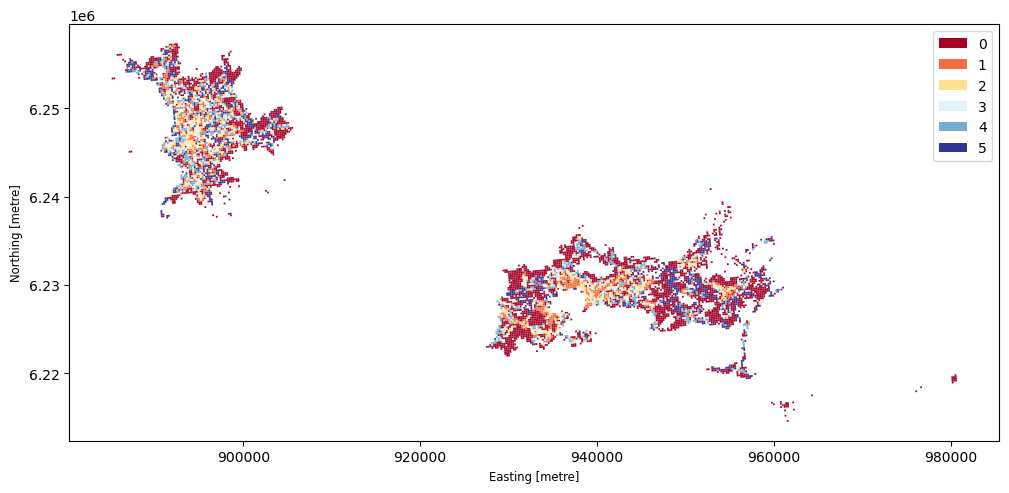

In [2]:
import geopandas as gpd, pandas as pd, numpy as np, os

# ---------- Paramètres ----------
notebookutils.fs.mount("abfss://citiz_hackathon@onelake.dfs.fabric.microsoft.com/lakehouse_silver.Lakehouse", "/silver")
notebookutils.fs.mount("abfss://citiz_hackathon@onelake.dfs.fabric.microsoft.com/lakehouse_gold.Lakehouse", "/gold")
S = notebookutils.fs.getMountPath("/silver") + "/Files"
G = notebookutils.fs.getMountPath("/gold") + "/Files/objectifs_1_2"
os.makedirs(G, exist_ok=True)

car = gpd.read_parquet(f"{S}/carreaux/carreaux_toulon_marseille.parquet").to_crs(2154)
opt = gpd.read_parquet(f"{S}/acces_5min/options.parquet").to_crs(2154)
acc = pd.read_parquet(f"{S}/acces_5min/acces_5min.parquet")
acc = acc.merge(car[["idcar_200m", "ind", "menages_sans_voiture_est"]], on="idcar_200m")

# ---------- OBJECTIF 2 : qui est desservi par chaque option ----------
P = acc.groupby("option_id").agg(habitants_5min=("ind", "sum"),
                                 menages_sans_voiture_5min=("menages_sans_voiture_est", "sum"))
nb_meme_type = acc.groupby(["idcar_200m", "type"])["option_id"].transform("nunique")
seul = acc[nb_meme_type == 1].groupby("option_id")["ind"].sum().rename("habitants_seule_option_du_type")
opt = opt.merge(P, on="option_id", how="left").merge(seul, on="option_id", how="left")
for c in ["habitants_5min", "menages_sans_voiture_5min", "habitants_seule_option_du_type"]:
    opt[c] = opt[c].fillna(0).round(0)

# ---------- OBJECTIF 1 : options par habitant (méthode 2SFCA) ----------
acc = acc.merge(P[["habitants_5min"]], on="option_id")
acc["part"] = np.where(acc.habitants_5min > 0, 1000 / acc.habitants_5min, 0)       # part de l'option pour 1000 hab
acc = acc.merge(opt[["option_id", "departs_heure_pointe"]], on="option_id", how="left")
acc["part_departs"] = np.where(acc.habitants_5min > 0, acc.departs_heure_pointe.fillna(0) * 1000 / acc.habitants_5min, 0)
A = acc.groupby("idcar_200m").agg(nb_options=("option_id", "nunique"),
                                  options_pour_1000_hab=("part", "sum"),
                                  departs_pointe_pour_1000_hab=("part_departs", "sum"))
car = car.merge(A, on="idcar_200m", how="left")
for c in ["nb_options", "options_pour_1000_hab", "departs_pointe_pour_1000_hab"]:
    car[c] = car[c].fillna(0)

# classes froid → chaud (par ville) : 0 = aucune option, puis 5 classes de même taille
noms = {0: "0 - aucune option", 1: "1 - très faible", 2: "2 - faible", 3: "3 - moyenne", 4: "4 - bonne", 5: "5 - très bonne"}
car["classe"] = 0
for v in car.ville.unique():
    m = (car.ville == v) & (car.options_pour_1000_hab > 0)
    car.loc[m, "classe"] = pd.qcut(car.loc[m, "options_pour_1000_hab"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
car["classe_nom"] = car.classe.map(noms)
car["masque_confidentialite"] = car["ind"] < 11          # carreaux très peu peuplés : à ne pas afficher seuls

# ---------- Sauvegarder dans lakehouse_gold ----------
cols_car = ["idcar_200m", "ville", "ind", "men", "menages_sans_voiture_est", "part_sans_voiture", "revenu_moyen",
            "nb_options", "options_pour_1000_hab", "departs_pointe_pour_1000_hab", "classe", "classe_nom",
            "masque_confidentialite", "geometry"]
carte = car[cols_car]
carte.to_parquet(f"{G}/carte_acces.parquet")
opt.to_parquet(f"{G}/options_desservies.parquet")

def vers_table(gdf, nom, wkt=False):
    t = pd.DataFrame(gdf.drop(columns="geometry"))
    p = gdf.to_crs(4326)
    c = gdf.centroid.to_crs(4326)
    t["lon"], t["lat"] = c.x, c.y
    if wkt: t["wkt"] = p.geometry.to_wkt()
    for col in t.columns:
        if t[col].dtype == object: t[col] = t[col].astype(str)
    sdf = spark.createDataFrame(t)
    try:    sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"lakehouse_gold.dbo.{nom}")
    except Exception: sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"lakehouse_gold.{nom}")
vers_table(carte, "carte_acces", wkt=True)
vers_table(opt, "options_desservies")
print("Sauvegardé : tables 'carte_acces' et 'options_desservies' dans lakehouse_gold")

# ---------- Carte objectif 1 ----------
carte.plot(column="classe", cmap="RdYlBu", legend=True, figsize=(12, 7), categorical=True)

In [3]:
print("=== OBJECTIF 1 : habitants par classe d'accès (%) ===")
t = car.pivot_table(index="classe_nom", columns="ville", values="ind", aggfunc="sum")
print((100 * t / t.sum()).round(1))

print("\n=== OBJECTIF 2 : les 10 options qui desservent le plus d'habitants, par ville ===")
for v in ["toulon", "marseille"]:
    print(f"\n--- {v} ---")
    print(opt[opt.ville == v].nlargest(10, "habitants_5min")[["type", "nom", "habitants_5min", "menages_sans_voiture_5min", "habitants_seule_option_du_type"]].to_string(index=False))

StatementMeta(, 85745e95-1b80-4846-aefa-4425cad3337c, 10, Finished, Available, Finished, False)

=== OBJECTIF 1 : habitants par classe d'accès (%) ===
ville              marseille  toulon
classe_nom                          
0 - aucune option       16.7    23.5
1 - très faible         24.6    30.3
2 - faible              22.3    22.6
3 - moyenne             17.1    13.9
4 - bonne               13.1     7.5
5 - très bonne           6.1     2.2

=== OBJECTIF 2 : les 10 options qui desservent le plus d'habitants, par ville ===

--- toulon ---
type               nom  habitants_5min  menages_sans_voiture_5min  habitants_seule_option_du_type
 bus            Carnot          4975.0                      977.0                             0.0
 bus             Pie X          4834.0                     1015.0                             0.0
 bus         Bazeilles          4765.0                      982.0                             0.0
 bus          Lamalgue          4765.0                      982.0                             0.0
 bus             Serre          4537.0                     10